In [1]:
import os, subprocess

try:
    import wordcloud
except ImportError:
    subprocess.run(['pip', 'install', '-q', 'wordcloud'])

NANUM = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if not os.path.exists(NANUM):
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

In [2]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

font_candidates = [
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    '/System/Library/Fonts/Supplemental/AppleGothic.ttf',
    'C:/Windows/Fonts/malgun.ttf',
    '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
]
font_path = next(p for p in font_candidates if os.path.exists(p))
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['axes.unicode_minus'] = False
print('사용 폰트:', font_path)

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9a9a9a', 'axes.titleweight': 'bold',
    'axes.titlesize': 14, 'figure.dpi': 110,
})

# 한국어 기사 분석과 같은 그룹 = 같은 색
GROUPS = ['bts', '세븐틴', '트와이스', '블랙핑크']
GROUP_LABEL = {'bts': 'BTS', '세븐틴': 'SEVENTEEN', '트와이스': 'TWICE', '블랙핑크': 'BLACKPINK'}
GROUP_COLOR = {'bts': '#2a78d6', '세븐틴': '#eb6834', '트와이스': '#1baf7a', '블랙핑크': '#e87ba4'}

사용 폰트: /usr/share/fonts/truetype/nanum/NanumGothic.ttf


In [3]:
# 코랩: 왼쪽 파일 탭에 processed_en.csv 업로드 후 실행
df = pd.read_csv('processed_en.csv')
df['tokens'] = df['tokens'].fillna('').str.split()
df['published_at'] = pd.to_datetime(df['published_at'])
df['year'] = df['published_at'].dt.year

print('문서 수:', len(df))
print('그룹별 기사 수:', df['group'].value_counts().to_dict())
print('기간:', df['published_at'].min().date(), '~', df['published_at'].max().date())
df[['group', 'source', 'title', 'published_at']].head()

문서 수: 800
그룹별 기사 수: {'블랙핑크': 200, 'bts': 200, '세븐틴': 200, '트와이스': 200}
기간: 2017-01-04 ~ 2026-10-02


,group,source,title,published_at
0,블랙핑크,popcrush.com,BLACKPINK Jisoo and Roseanne Cover Justin Bieb...,2017-01-13 03:45:00
1,블랙핑크,ohnotheydidnt.livejournal.com,"CL talks 2NE1 GOODBYE , Minzy , US Solo Career...",2017-01-23 07:15:00
2,블랙핑크,popcrush.com,BLACKPINK Dominate the Stage and Win at 6th An...,2017-02-24 07:15:00
3,블랙핑크,popcrush.com,BLACKPINK vs . Apink : March Madness 2017 — B...,2017-03-02 04:45:00
4,블랙핑크,en.yibada.com,BLACKPINK Lisa still asking for purple hearts ...,2017-03-08 03:45:00


In [4]:
EXCLUDE_GROUPS = {'베이비몬스터', '코르티스', 'babymonster', 'cortis'}
EXCLUDE_PATTERN = re.compile(r'baby\s?monster|cortis|베이비몬스터|코르티스', re.IGNORECASE)

n0 = len(df)
mask_group = df['group'].str.lower().isin(EXCLUDE_GROUPS)
mask_mention = (df['title'].fillna('') + ' ' + df['text'].fillna('')).str.contains(EXCLUDE_PATTERN)

print('① group 컬럼 기준 제외:', mask_group.sum(), '건')
print('② 제목·본문 언급 기준 제외:', (mask_mention & ~mask_group).sum(), '건')
print(df.loc[mask_mention & ~mask_group, ['group', 'title']].to_string())

df = df[~(mask_group | mask_mention)].reset_index(drop=True)
print(f'\n문서 수: {n0} → {len(df)}')

① group 컬럼 기준 제외: 0 건
② 제목·본문 언급 기준 제외: 2 건
    group                                                                                                                    title
176  블랙핑크                                                                        Here when BLACKPINK will be releasing a new album
387   bts  BTS , CORTIS , LE SSERAFIM to KATSEYE : Inside HYBE India Mumbai Pop - Up Park that turned into a mini K - pop festival

문서 수: 800 → 798


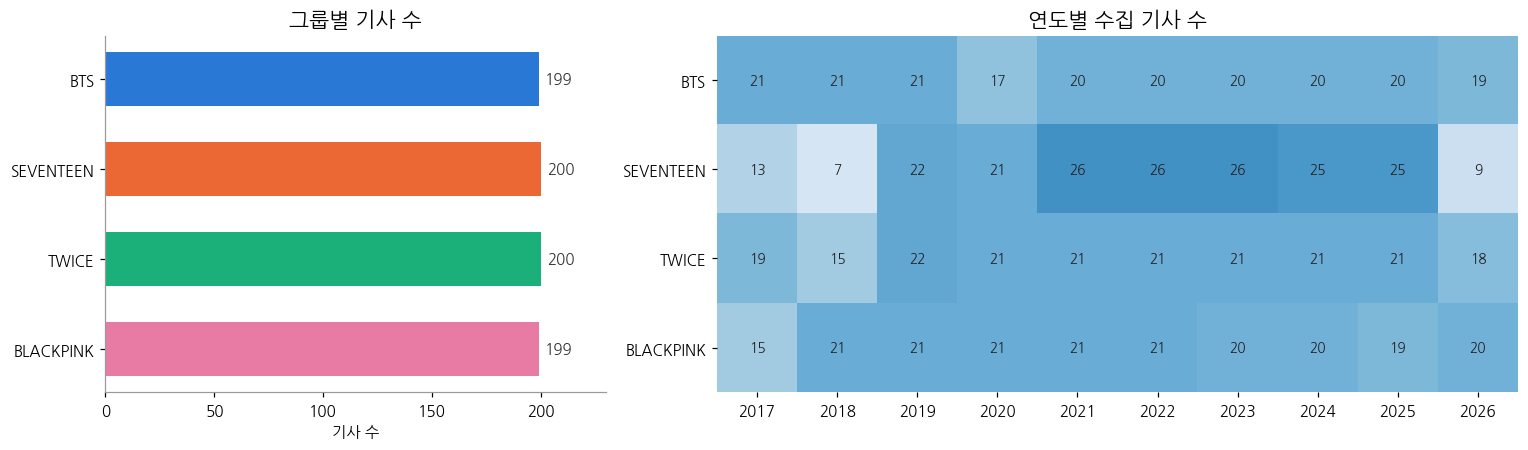

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})

cnt = df['group'].value_counts().reindex(GROUPS)
ax = axes[0]
ax.barh([GROUP_LABEL[g] for g in GROUPS][::-1], cnt.values[::-1],
        color=[GROUP_COLOR[g] for g in GROUPS][::-1], height=0.6)
for i, v in enumerate(cnt.values[::-1]):
    ax.text(v + 3, i, f'{v}', va='center', fontsize=10, color='#333')
ax.set_title('그룹별 기사 수')
ax.set_xlabel('기사 수')
ax.set_xlim(0, cnt.max() * 1.15)

ct = pd.crosstab(df['group'], df['year']).reindex(GROUPS)
ax = axes[1]
ax.imshow(ct.values, cmap='Blues', aspect='auto', vmin=0, vmax=ct.values.max() * 1.6)
ax.set_xticks(range(len(ct.columns)), ct.columns)
ax.set_yticks(range(len(GROUPS)), [GROUP_LABEL[g] for g in GROUPS])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, ct.values[i, j], ha='center', va='center', fontsize=9, color='#222')
ax.set_title('연도별 수집 기사 수')
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

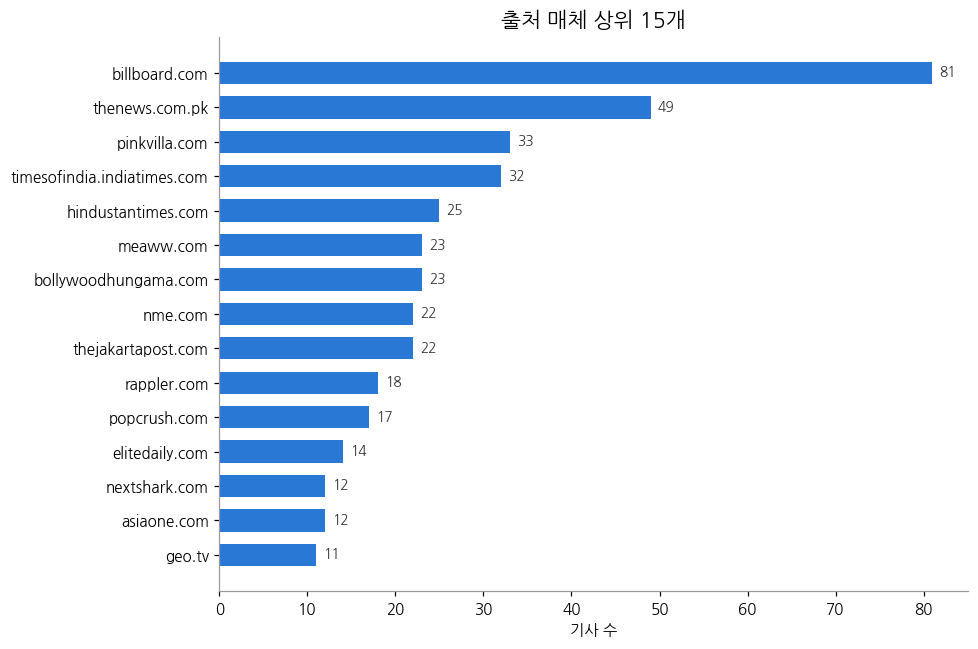

전체 매체 수: 202개, 상위 15개 비중: 49.4%


In [6]:
# 출처 매체 상위 15개 – 어느 나라 매체가 K-pop을 많이 다루는가
src = df['source'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(src.index[::-1], src.values[::-1], color='#2a78d6', height=0.65)
for i, v in enumerate(src.values[::-1]):
    ax.text(v + 0.8, i, v, va='center', fontsize=9, color='#333')
ax.set_title('출처 매체 상위 15개')
ax.set_xlabel('기사 수')
plt.tight_layout()
plt.show()
print(f'전체 매체 수: {df["source"].nunique()}개, 상위 15개 비중: {src.sum() / len(df):.1%}')

In [7]:
before = Counter(t for ts in df['tokens'] for t in ts)
print('고유 단어 수:', len(before), '/ 전체 토큰 수:', sum(before.values()))
print(before.most_common(40))

고유 단어 수: 11579 / 전체 토큰 수: 154030
[('fan', 1830), ('album', 1744), ('release', 1218), ('world', 887), ('korean', 849), ('tour', 791), ('chart', 737), ('debut', 713), ('love', 696), ('south', 695), ('entertainment', 686), ('artist', 656), ('track', 640), ('concert', 639), ('single', 597), ('korea', 583), ('billboard', 561), ('hit', 560), ('good', 535), ('perform', 534), ('solo', 500), ('lisa', 493), ('big', 484), ('star', 478), ('performance', 474), ('include', 461), ('week', 443), ('share', 439), ('global', 421), ('day', 419), ('record', 398), ('feature', 396), ('act', 392), ('set', 389), ('stage', 381), ('date', 381), ('post', 380), ('follow', 378), ('late', 375), ('award', 368)]


In [8]:
STOPWORDS = set('''
good big include week share day set date follow late work announce month continue lead
start end way write accord add bring read find hold number reveal confirm high different
lot old young update begin change place need try tell ask leave bear stay today run spot
mark second report post come make take get go know say look want use give think see time
year new first just also like well many much may might could would will one two three
last next back even still really thing part long put call keep show feel seem become
january february march april may june july august september october november december
monday tuesday wednesday thursday friday saturday sunday sun com www http https news
bollywood
'''.split())
# sun: 'Sunday'가 잘린 조각·인명 일부 / bollywood: bollywoodhungama.com 기사 하단 고정 문구
# ("BOLLYWOOD NEWS - LIVE UPDATES ...")가 본문에 섞여 들어온 것

KEEP_SHORT = {'rm', 'dk', 'ep', 'yg'}

def clean(tokens):
    return [t for t in tokens
            if t not in STOPWORDS and (len(t) > 2 or t in KEEP_SHORT)]

df['clean'] = df['tokens'].apply(clean)
tb, ta = df['tokens'].str.len().sum(), df['clean'].str.len().sum()
print(f'토큰 수: {tb:,} → {ta:,} ({ta/tb:.1%} 유지)')

토큰 수: 154,030 → 135,759 (88.1% 유지)


[('fan', 1830), ('album', 1744), ('release', 1218), ('world', 887), ('korean', 849), ('tour', 791), ('chart', 737), ('debut', 713), ('love', 696), ('south', 695), ('entertainment', 686), ('artist', 656), ('track', 640), ('concert', 639), ('single', 597), ('korea', 583), ('billboard', 561), ('hit', 560), ('perform', 534), ('solo', 500)]


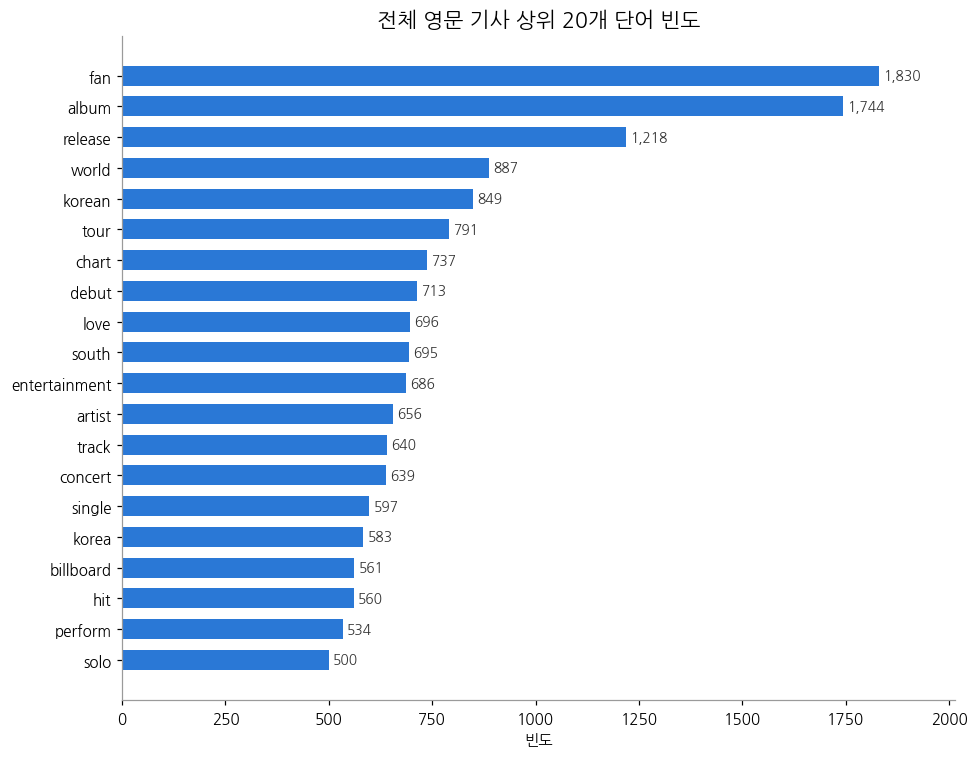

In [9]:
word_count = Counter(t for ts in df['clean'] for t in ts)
top20 = word_count.most_common(20)
print(top20)

words, freqs = zip(*top20)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(words[::-1], freqs[::-1], color='#2a78d6', height=0.65)
for i, v in enumerate(freqs[::-1]):
    ax.text(v + 10, i, f'{v:,}', va='center', fontsize=9, color='#333')
ax.set_title('전체 영문 기사 상위 20개 단어 빈도')
ax.set_xlabel('빈도')
ax.set_xlim(0, max(freqs) * 1.1)
plt.tight_layout()
plt.show()

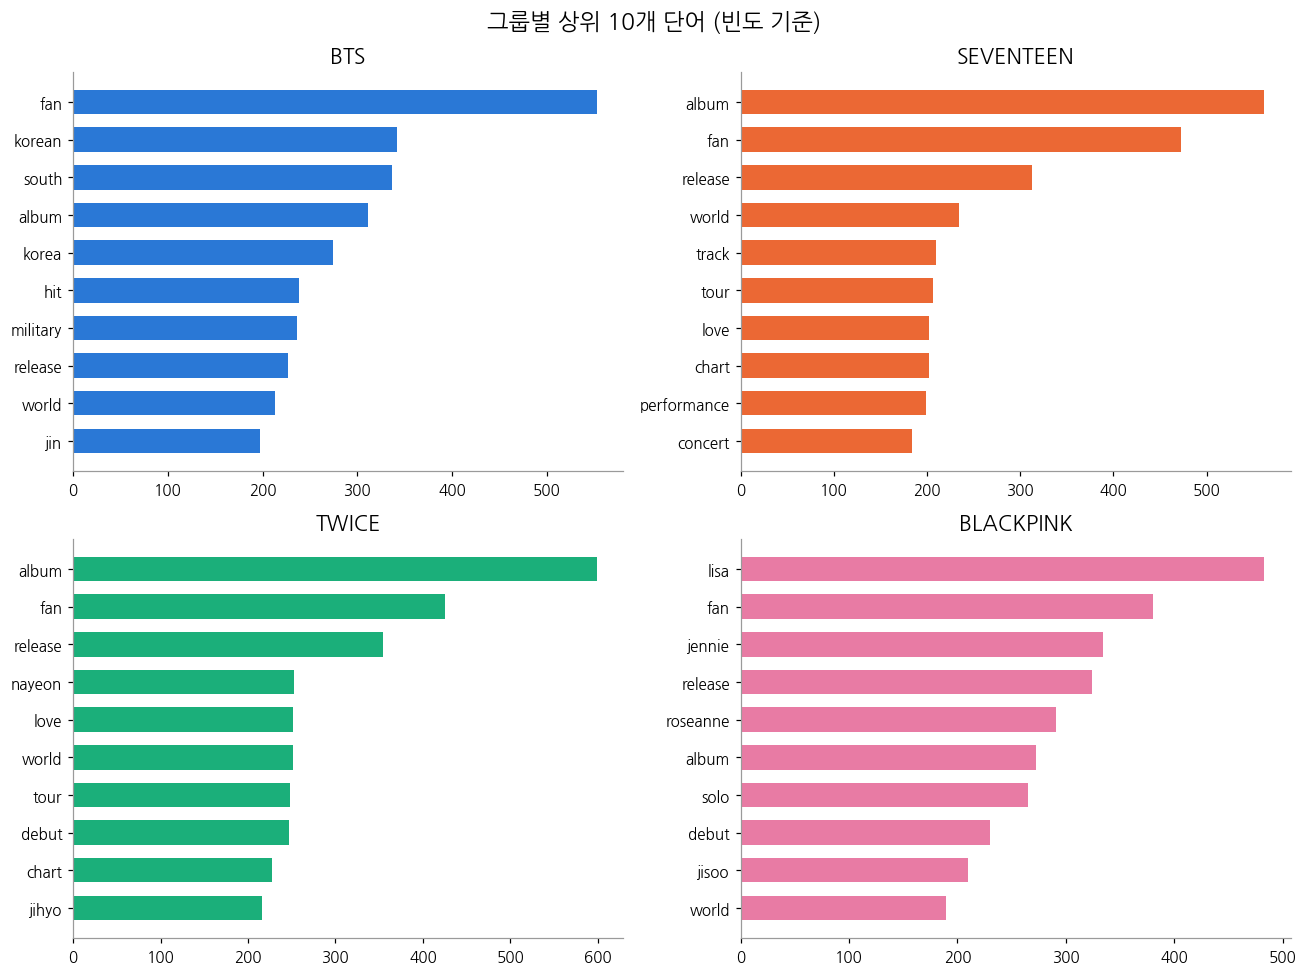

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, g in zip(axes.flat, GROUPS):
    c = Counter(t for ts in df.loc[df['group'] == g, 'clean'] for t in ts)
    w, f = zip(*c.most_common(10))
    ax.barh(w[::-1], f[::-1], color=GROUP_COLOR[g], height=0.65)
    ax.set_title(GROUP_LABEL[g])
fig.suptitle('그룹별 상위 10개 단어 (빈도 기준)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

고유 단어 11,292개 중 상위 100개(약 0.9%)가 전체 사용량의 26.5% 차지


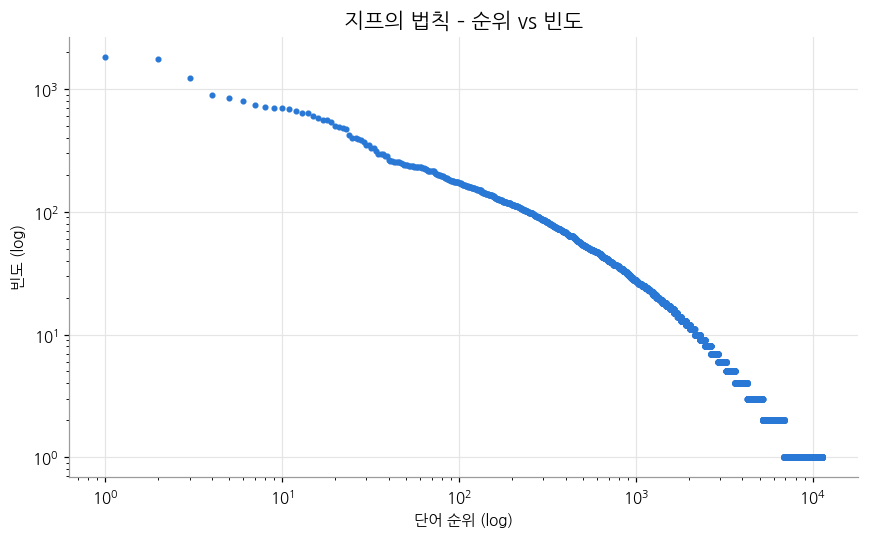

In [11]:
freq_sorted = np.array(sorted(word_count.values(), reverse=True))
rank = np.arange(1, len(freq_sorted) + 1)

top100_share = freq_sorted[:100].sum() / freq_sorted.sum()
print(f'고유 단어 {len(freq_sorted):,}개 중 상위 100개(약 {100/len(freq_sorted):.1%})가 '
      f'전체 사용량의 {top100_share:.1%} 차지')

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(rank, freq_sorted, marker='o', markersize=3, linewidth=0, color='#2a78d6')
ax.set_xlabel('단어 순위 (log)')
ax.set_ylabel('빈도 (log)')
ax.set_title('지프의 법칙 – 순위 vs 빈도')
ax.grid(True, which='major', color='#e5e5e5', linewidth=0.8)
plt.tight_layout()
plt.show()

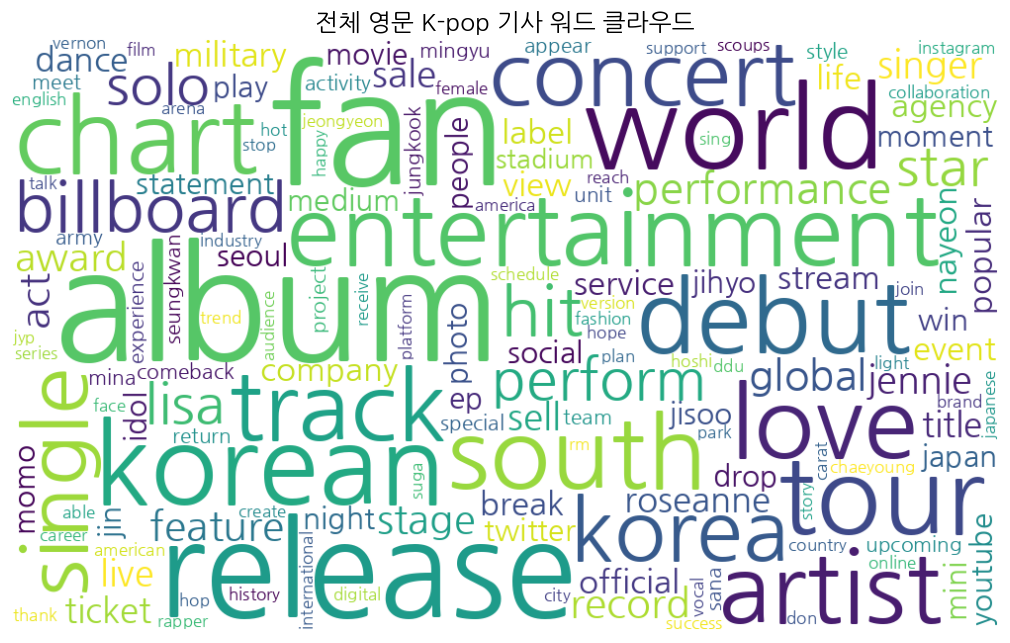

In [12]:
wc = WordCloud(font_path=font_path, width=1000, height=600,
               background_color='white', max_words=150,
               max_font_size=160, colormap='viridis', random_state=42)
wc.generate_from_frequencies(word_count)

plt.figure(figsize=(12, 7))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('전체 영문 K-pop 기사 워드 클라우드', fontsize=16, fontweight='bold')
plt.show()

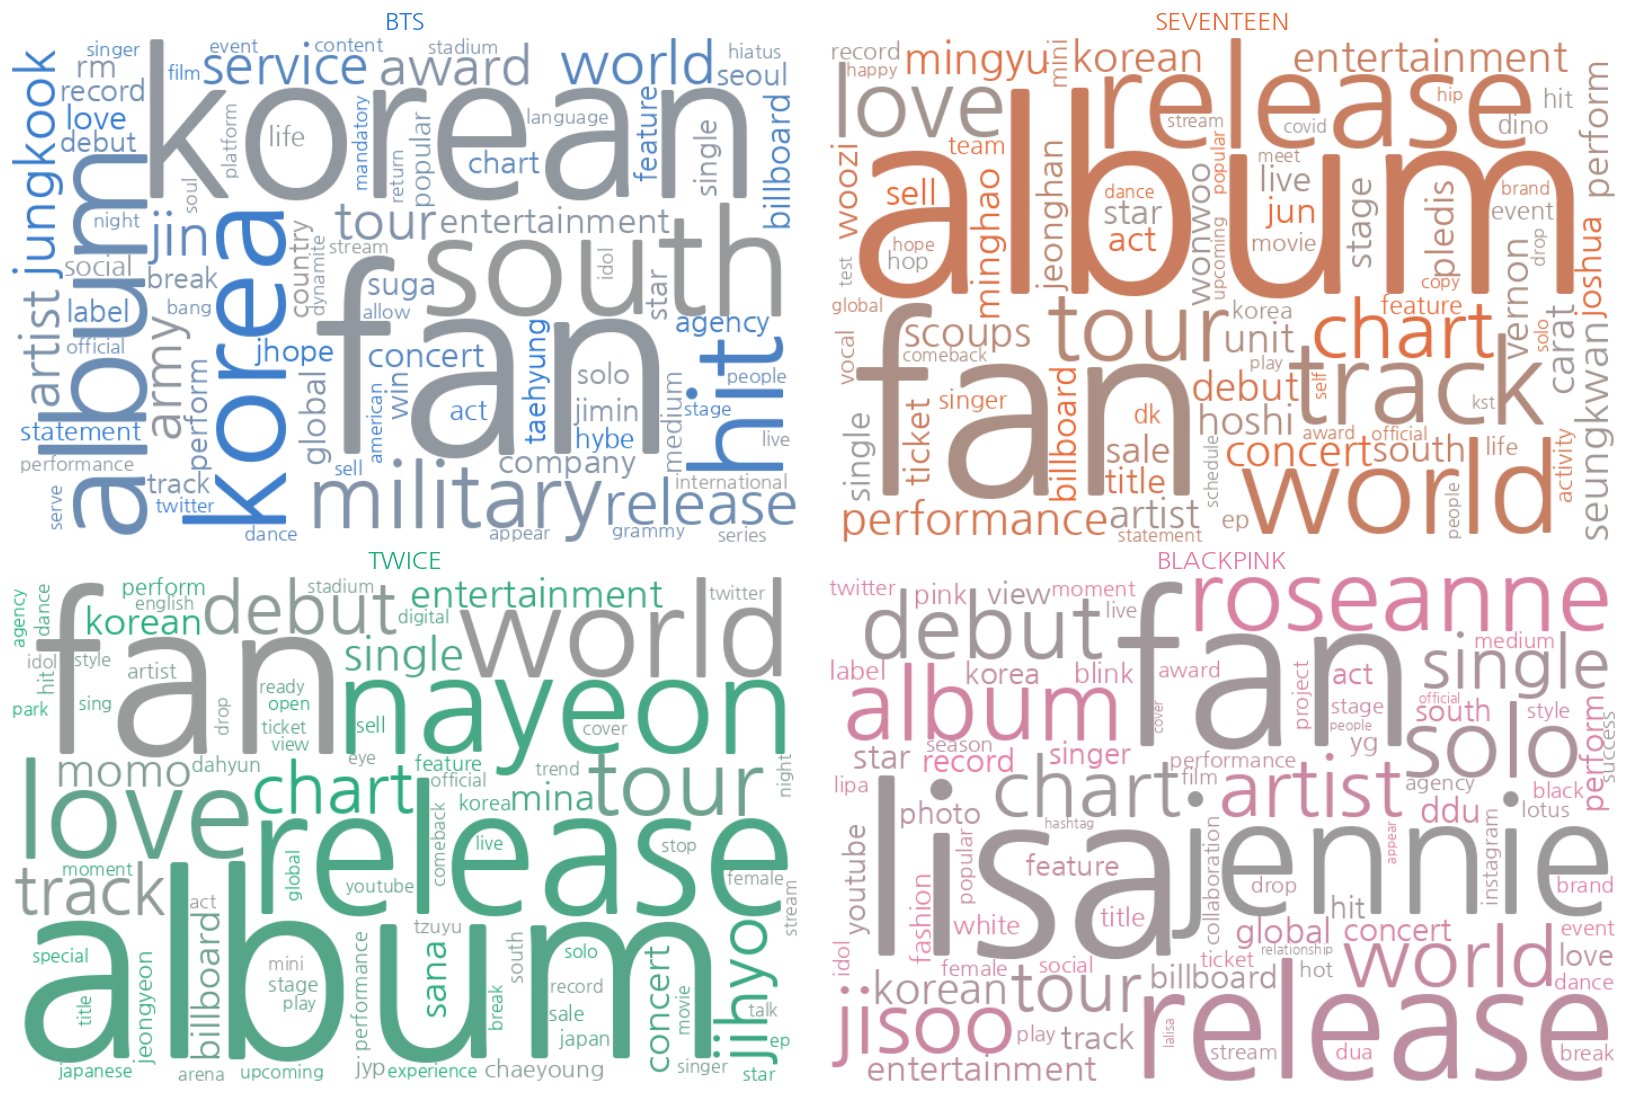

In [13]:
from matplotlib.colors import LinearSegmentedColormap

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, g in zip(axes.flat, GROUPS):
    freq = Counter(t for ts in df.loc[df['group'] == g, 'clean'] for t in ts)
    cmap = LinearSegmentedColormap.from_list(g, ['#9a9a9a', GROUP_COLOR[g]])
    wc_g = WordCloud(font_path=font_path, width=700, height=450,
                     background_color='white', max_words=80,
                     colormap=cmap, random_state=42).generate_from_frequencies(freq)
    ax.imshow(wc_g, interpolation='bilinear')
    ax.set_title(GROUP_LABEL[g], fontsize=16, fontweight='bold', color=GROUP_COLOR[g])
    ax.axis('off')
plt.tight_layout()
plt.show()

TF-IDF 행렬 크기 (문서 수, 특성 수): (798, 4570)


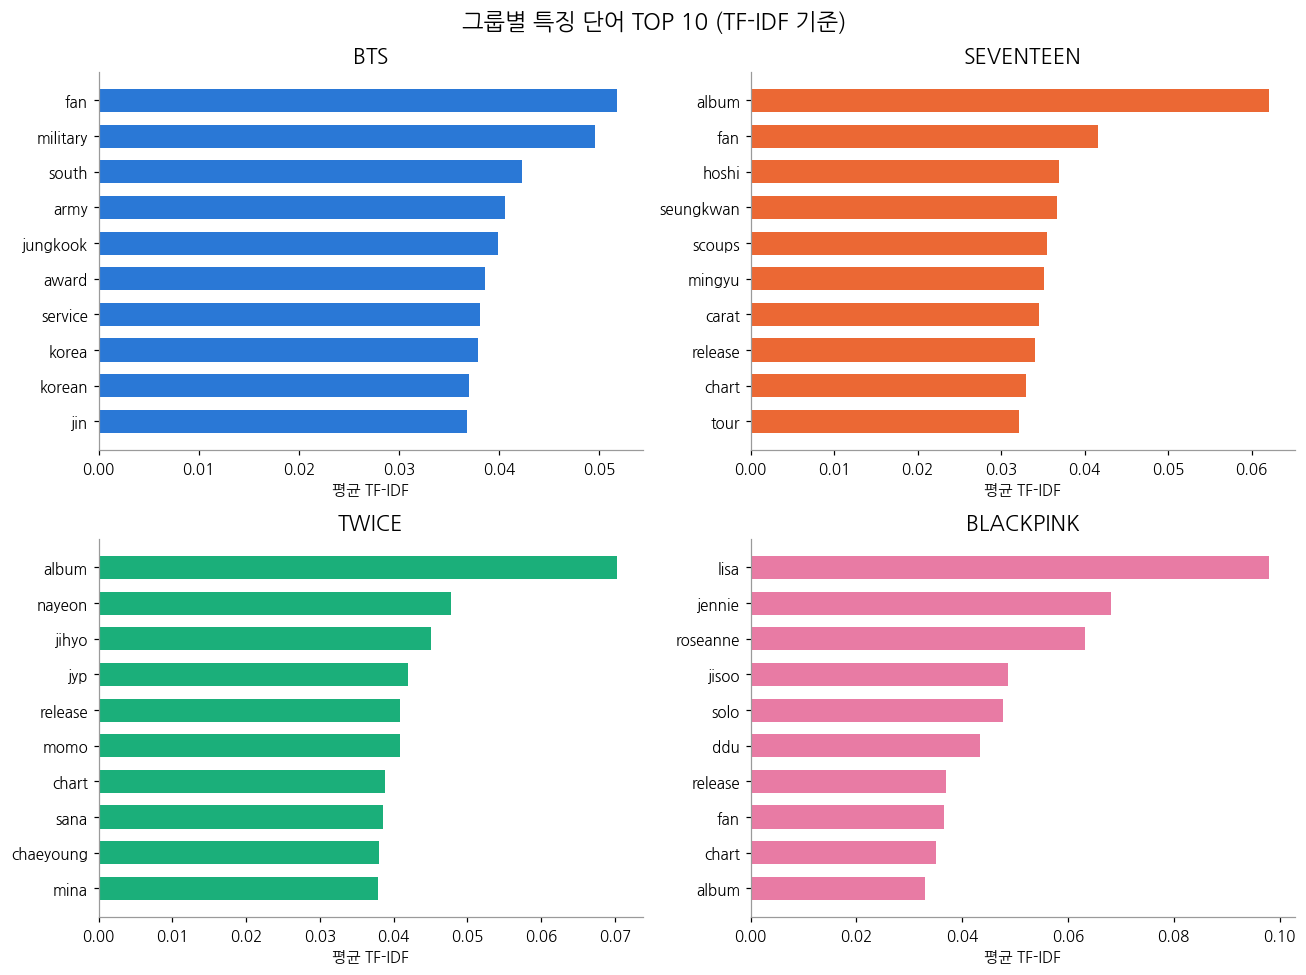

In [14]:
docs = df['clean'].apply(' '.join)
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=3)
X_tfidf = tfidf.fit_transform(docs)
vocab = tfidf.get_feature_names_out()
print('TF-IDF 행렬 크기 (문서 수, 특성 수):', X_tfidf.shape)

group_tfidf = pd.DataFrame(
    {g: np.asarray(X_tfidf[(df['group'] == g).values].mean(axis=0)).ravel() for g in GROUPS},
    index=vocab)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, g in zip(axes.flat, GROUPS):
    top = group_tfidf[g].nlargest(10)[::-1]
    ax.barh(top.index, top.values, color=GROUP_COLOR[g], height=0.65)
    ax.set_title(GROUP_LABEL[g])
    ax.set_xlabel('평균 TF-IDF')
fig.suptitle('그룹별 특징 단어 TOP 10 (TF-IDF 기준)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

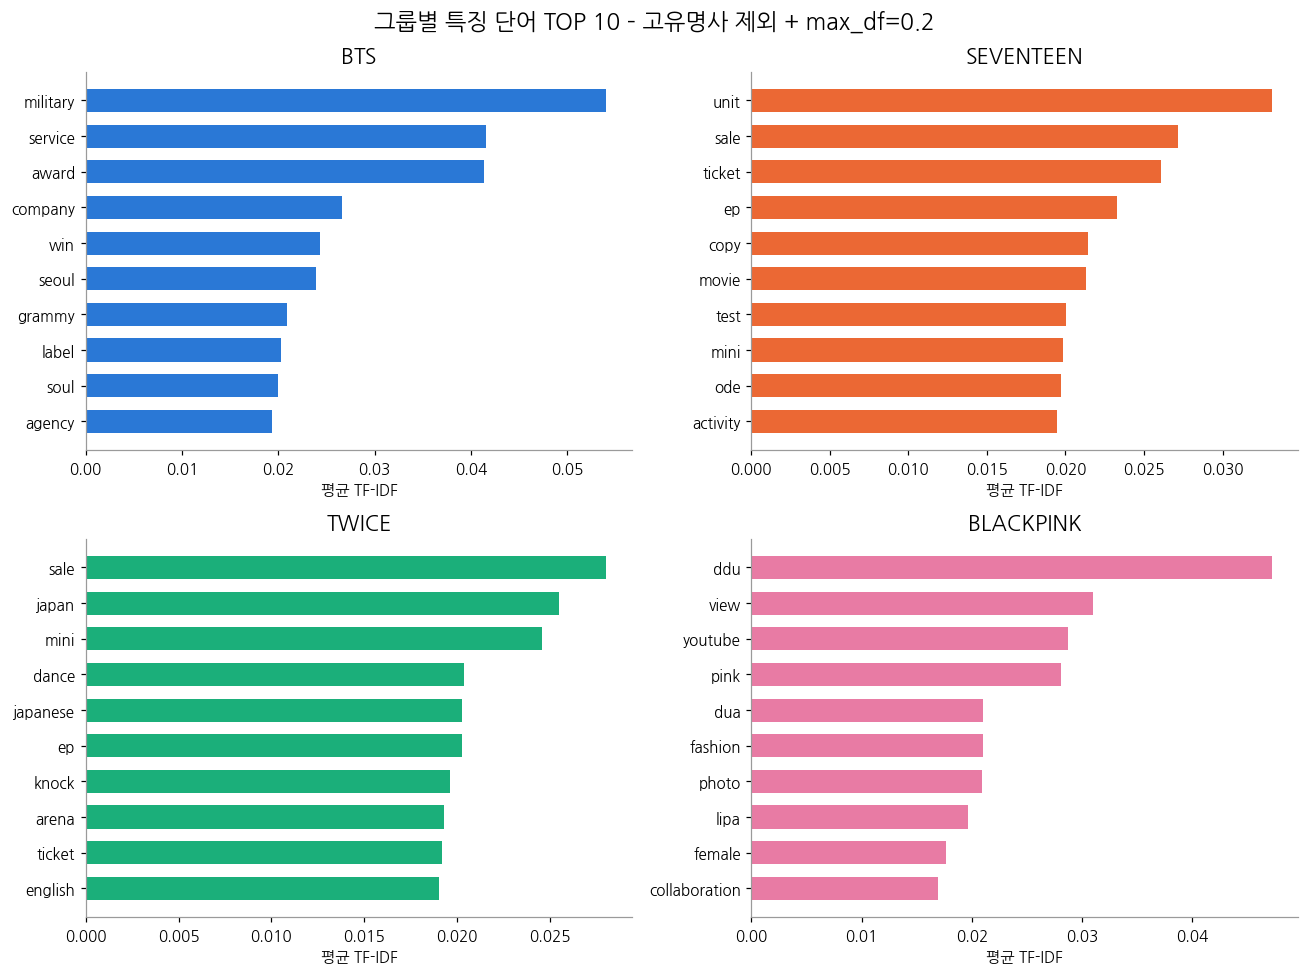

In [15]:
NAMES = set('''
rm namjoon suga yoongi jhope hoseok jimin taehyung jin seokjin jungkook
scoups seungcheol jeonghan joshua jun hoshi wonwoo woozi dino mingyu dk dokyeom seungkwan vernon minghao
nayeon jeongyeon momo sana jihyo mina dahyun chaeyoung tzuyu
jisoo jennie rose roseanne lisa
hybe bighit jyp yg pledis
army carat blink
'''.split())

docs_topic = df['clean'].apply(lambda ts: ' '.join(t for t in ts if t not in NAMES))
# max_df=0.2: 전체 기사의 20% 넘게 등장하는 공통어(fan, album, release …)는 특성에서 제외
tfidf_t = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                          min_df=3, max_df=0.2)
X_topic = tfidf_t.fit_transform(docs_topic)
group_topic = pd.DataFrame(
    {g: np.asarray(X_topic[(df['group'] == g).values].mean(axis=0)).ravel() for g in GROUPS},
    index=tfidf_t.get_feature_names_out())

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, g in zip(axes.flat, GROUPS):
    top = group_topic[g].nlargest(10)[::-1]
    ax.barh(top.index, top.values, color=GROUP_COLOR[g], height=0.65)
    ax.set_title(GROUP_LABEL[g])
    ax.set_xlabel('평균 TF-IDF')
fig.suptitle('그룹별 특징 단어 TOP 10 – 고유명사 제외 + max_df=0.2', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

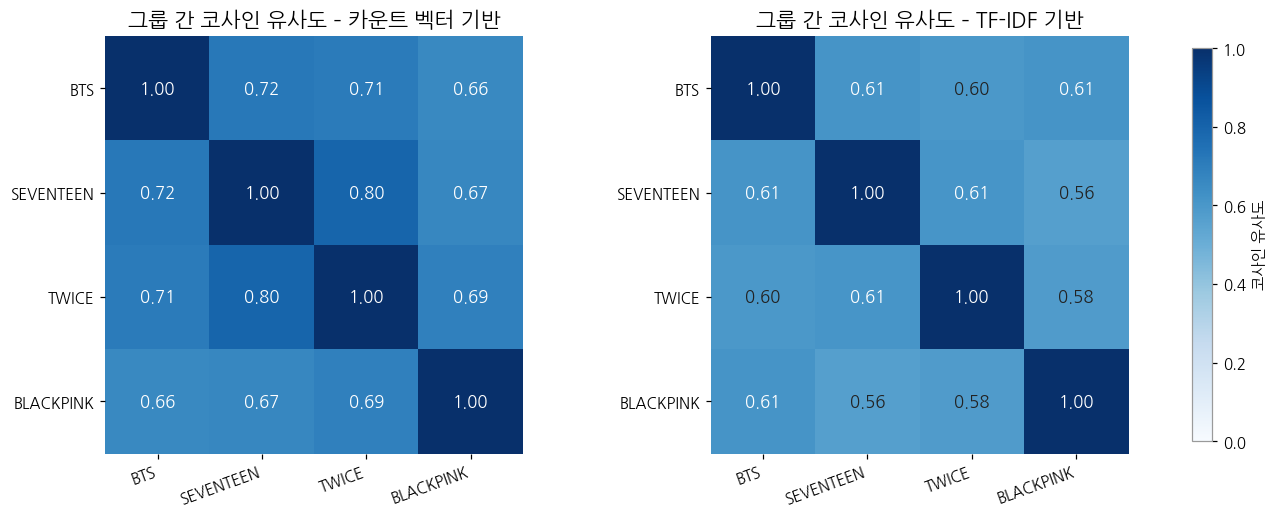

In [16]:
group_docs = [' '.join(' '.join(ts) for ts in df.loc[df['group'] == g, 'clean']) for g in GROUPS]

cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)
sim_count = cosine_similarity(cv.fit_transform(group_docs))
tv = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)
sim_tfidf = cosine_similarity(tv.fit_transform(group_docs))

labels = [GROUP_LABEL[g] for g in GROUPS]
n = len(GROUPS)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
fig.subplots_adjust(wspace=0.45)
for ax, sim, title in zip(axes, [sim_count, sim_tfidf], ['카운트 벡터 기반', 'TF-IDF 기반']):
    im = ax.imshow(sim, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n), labels, rotation=20, ha='right')
    ax.set_yticks(range(n), labels)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{sim[i, j]:.2f}', ha='center', va='center', fontsize=11,
                    color='white' if sim[i, j] > 0.6 else '#222')
    ax.set_title(f'그룹 간 코사인 유사도 – {title}')
    ax.spines[:].set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label='코사인 유사도')
plt.show()

In [17]:
query_idx = 0                                   # 다른 번호로 바꿔서 실험해 보기
sims = cosine_similarity(X_tfidf[query_idx], X_tfidf).ravel()
order = sims.argsort()[::-1][1:6]

print('[기준 기사]', GROUP_LABEL[df.loc[query_idx, 'group']], '|', df.loc[query_idx, 'title'])
pd.DataFrame({'유사도': sims[order].round(3),
              '그룹': df.loc[order, 'group'].map(GROUP_LABEL).values,
              '날짜': df.loc[order, 'published_at'].dt.date.values,
              '제목': df.loc[order, 'title'].values})

[기준 기사] BLACKPINK | BLACKPINK Jisoo and Roseanne Cover Justin Bieber  Love Yourself


,유사도,그룹,날짜,제목
0,0.321,TWICE,2017-06-01,Justin Bieber vs . TWICE : 2017 Summer Fan Sho...
1,0.274,BLACKPINK,2021-09-11,Blackpink now most subscribed artist on YouTube
2,0.211,BLACKPINK,2026-03-21,BLACKPINK Roseanne reveals one skill she hasnt...
3,0.205,BLACKPINK,2021-11-28,BLACKPINK crowned YouTube most followed celebrity
4,0.203,BLACKPINK,2021-04-07,Roseanne from BLACKPINK Does Cardi B WAP Cha...


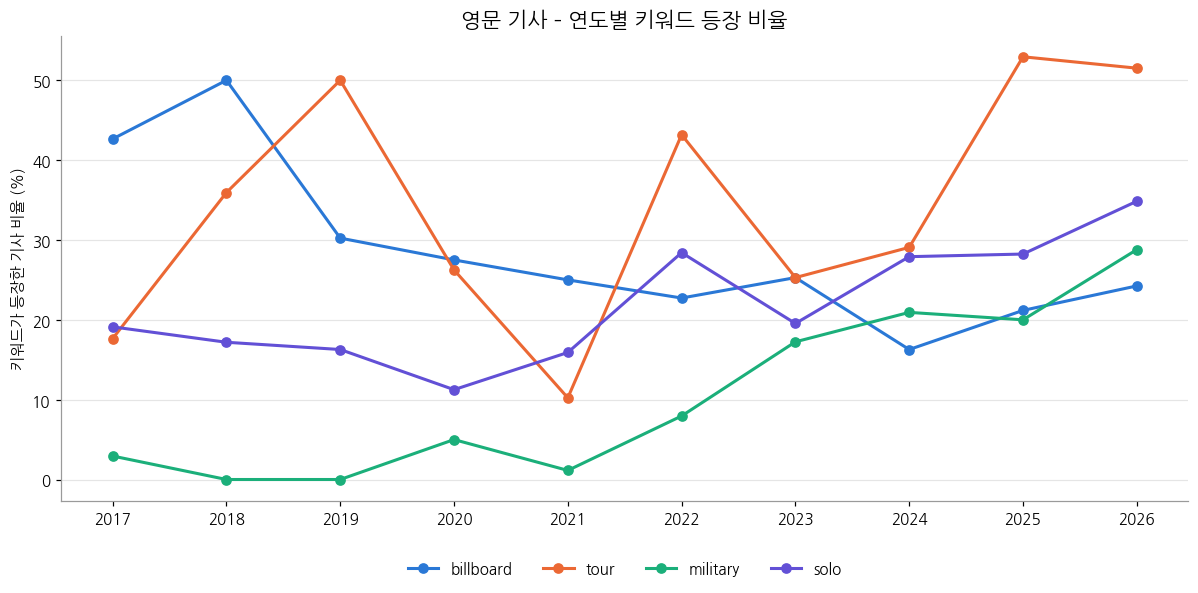

,billboard,tour,military,solo
year,,,,
2017,42.6,17.6,2.9,19.1
2018,50.0,35.9,0.0,17.2
2019,30.2,50.0,0.0,16.3
2020,27.5,26.2,5.0,11.2
2021,25.0,10.2,1.1,15.9
2022,22.7,43.2,8.0,28.4
2023,25.3,25.3,17.2,19.5
2024,16.3,29.1,20.9,27.9
2025,21.2,52.9,20.0,28.2


In [18]:
KEYWORDS = ['billboard', 'tour', 'military', 'solo']
KW_COLOR = ['#2a78d6', '#eb6834', '#1baf7a', '#6250d6']

trend = pd.DataFrame({kw: df.groupby('year')['clean'].apply(lambda s: s.apply(lambda ts: kw in ts).mean())
                      for kw in KEYWORDS}) * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
for kw, c in zip(KEYWORDS, KW_COLOR):
    ax.plot(trend.index, trend[kw], color=c, linewidth=2, marker='o', markersize=6, label=kw)
ax.set_xticks(trend.index)
ax.set_ylabel('키워드가 등장한 기사 비율 (%)')
ax.set_title('영문 기사 – 연도별 키워드 등장 비율')
ax.grid(axis='y', color='#e5e5e5')
ax.legend(frameon=False, loc='upper center', ncol=4, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()
trend.round(1)